# Start ×1 tegenover ×64 — tien leerbare schaalkeuzes, honderd epochs

**SVHN · CNN-8 · E4M3 → E2M3 → E2M1 · A32 · FP32-mastergewichten · B32**

Deze training onderzoekt de invloed van de **initialisatie** van de schaalparameters. De nieuwe run begint met alle 4.080 parameters op **θ = 0, dus factor ×1**. De eerdere volledige referentie begon op **θ = 6, dus ×64**. De tien factoren ×1, ×2, ×4, ×8, ×16, ×32, ×64, ×128, ×256 en ×512 blijven vrij leerbaar.

De nieuwe 100-epochrun start opnieuw vanaf de oorspronkelijke gewichten en BatchNorm-toestand. Het vijf-epochcheckpoint is geen warmstart. **Gewichten én schaalparameters leren tot epoch 100; er is geen bevriezing op 50.** De oorspronkelijke learningratemijlpalen50/75/90 blijven behouden.

×1 betekent **S_E2 = S_E4 per groep**, geen absolute schaal1. De E4M3-bronschaal wordt nog steeds uit de actuele gewichten bepaald; E2M3 en E2M1 delen hun lagere schaal. Dit is een initialisatiecontrole binnen de bestaande verhoudingsmethode, vóór de latere proef met onafhankelijke schalen.

**Bronnen:** eigen opgeslagen `history.json`, `run_report.json` en tabellen, de vastgelegde historische init×64-run en de afzonderlijke init×1-pilot. De notebook start geen training of nieuwe inferentie. Ontbrekende waarden worden niet ingevuld.

In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_learned_scale10_init1_reference100\\20261111_133712_391424_joint_run')
SAVE_FIGURES = False


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str): pass
    def display(value): print(value)

helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
if not helper_path.is_file():
    raise FileNotFoundError('Zet RUN_DIR op de resultatenmap van de init×1-training: ' + str(helper_path.parent))
spec = importlib.util.spec_from_file_location('_mx_scale10_init1_reference100_analysis', helper_path)
ns = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(pd.DataFrame(run.issues, columns=['Niveau', 'Melding']))


### Honderd epochs voltooid

Runstatus: **PASS** · laatste afgeronde epoch: **100** · analysefouten: **0**. Historische init×64-vergelijking: **bevestigd, 100 gemeten epochs**.

Epoch100 is gemeten en bevestigd. De nieuwe training begint bij epoch0 en leert zowel gewichten als schaalparameters tot epoch100; er is geen bevriezing op50. De notebook leest alleen opgeslagen JSON/CSV en start geen training.

,Onderdeel,Afspraak
0,Onderzoeksvraag,Beïnvloedt starten bij ×1 in plaats van ×64 he...
1,Enige bedoelde numerieke wijziging tegenover i...,Alle4.080 schaalparameters beginnen op θ=0 in ...
2,Betekenis ×1,S_E2 = S_E4 per groep; geen absolute schaal1. ...
3,Tien vrije keuzes,"×1, ×2, ×4, ×8, ×16, ×32, ×64, ×128, ×256, ×512"
4,Gewichtsroute,E4M3 → exponent-MSB-truncatie → E2M3 → mantiss...
5,Duur en leren,100epochs vanaf dezelfde oorspronkelijke FP32-...
6,Activaties / masters / groepen,A32 / FP32 / B32
7,Leerinstellingen,Adam; gewichts-LR0.001; schaal-LR0.001; oorspr...
8,Schaalgradient,Bestaande ln(2) × som(gradient_q × werkelijk q...
9,Vergelijking,Beginweights/BN en seed gelijk; samplevolgorde...


,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## 1. Volledig accuracyverloop

De drie precisiepanelen delen dezelfde y-as. Die volgt de werkelijk getoonde scores: nauwe verschillen worden ingezoomd; lage vroege accuracies blijven zichtbaar. Er wordt niets gladgestreken. Een historische curve stopt zodra daarvoor geen metingen beschikbaar zijn. De verticale stippellijnen markeren de oorspronkelijke LR-mijlpalen 50/75/90.

Historische init×64-run: **100epochs**; nieuwe init×1-run: **100epochs**. Gepaarde beste-checkpointselectie gebruikt voor beide het venster **1–100**. De volledige nieuwe curve en de eigen checkpointselectie blijven apart beschikbaar. Een vergelijking op epoch100 verschijnt alleen als beide volledige100-epochruns bevestigd zijn.

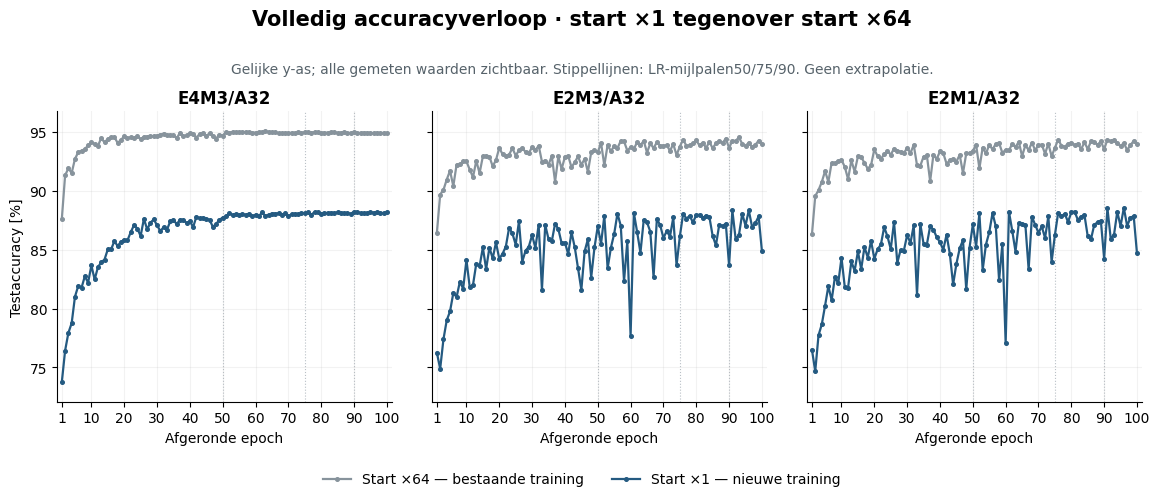

In [3]:
display(Markdown(ns.comparison_markdown(run)))
figures['accuracy_verloop'] = ns.plot_initialization_accuracy(run)
display(figures['accuracy_verloop'])
plt.close(figures['accuracy_verloop'])


## 2. Eigen eindpunt en eigen beste checkpoint

Epoch100 is het vaste eindpunt en verschijnt pas als alle honderd epochs voor alle drie modi bevestigd zijn. Tijdens een deelrun staat de laatste afgeronde epoch apart. Het beste checkpoint is het **eerste hoogste E4M3-testresultaat** binnen de werkelijk gemeten nieuwe training. E2M3 en E2M1 worden op diezelfde epoch gerapporteerd; hun afzonderlijke maxima worden niet gecombineerd.

,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE
0,epoch100,Epoch100,100,MXFP8_E4M3,88.195298,22.959 / 26.032,0.388170
1,epoch100,Epoch100,100,MXFP6_E2M3,84.883989,22.097 / 26.032,0.479212
2,epoch100,Epoch100,100,MXFP4_E2M1,84.684235,22.045 / 26.032,0.486588
3,best_E4M3_test,Beste checkpoint gekozen door E4M3,90,MXFP8_E4M3,88.206822,22.962 / 26.032,0.386502
4,best_E4M3_test,Beste checkpoint gekozen door E4M3,90,MXFP6_E2M3,83.662415,21.779 / 26.032,0.554158
5,best_E4M3_test,Beste checkpoint gekozen door E4M3,90,MXFP4_E2M1,84.227105,21.926 / 26.032,0.550143


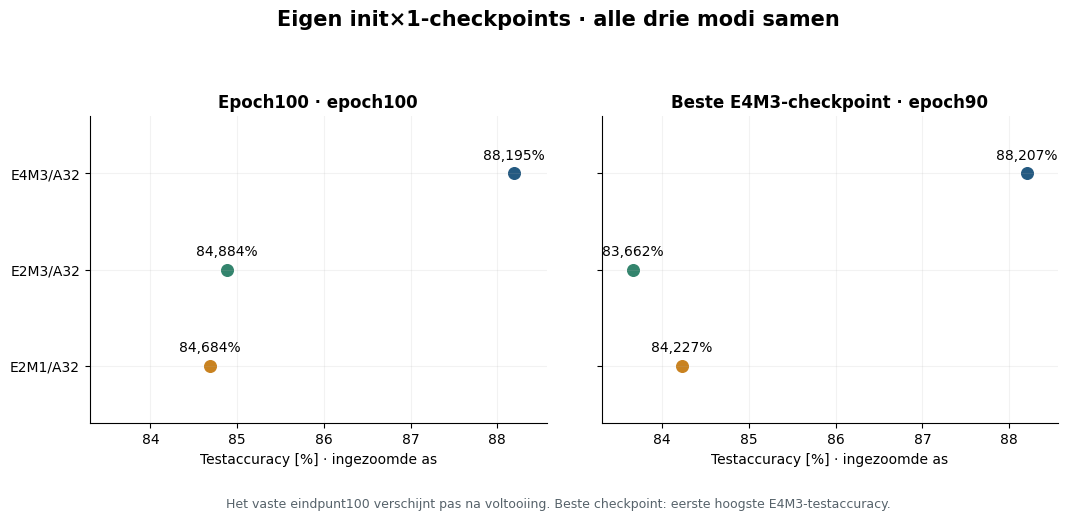

In [4]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['eigen_checkpoints'] = ns.plot_checkpoint_accuracy(run)
display(figures['eigen_checkpoints'])
plt.close(figures['eigen_checkpoints'])


## 3. Vergelijking op epoch 100

Dit is de vooraf gekozen eindpuntvergelijking tussen beide initialisaties. Zij blijft leeg zolang niet beide volledige 100-epochresultaten bevestigd zijn. De punten gebruiken een ingezoomde as; er is geen afgekorte staaf die het verschil groter doet lijken.

,Variant,Epoch,Precisie,Testaccuracy [%],Correct,Testbeelden,Selectievenster
0,Start ×64 — bestaande training,100,E4M3,94.871696,24697,26032,Vast epoch100
1,Start ×64 — bestaande training,100,E2M3,93.934388,24453,26032,Vast epoch100
2,Start ×64 — bestaande training,100,E2M1,93.961278,24460,26032,Vast epoch100
3,Start ×1 — nieuwe training,100,E4M3,88.195298,22959,26032,Vast epoch100
4,Start ×1 — nieuwe training,100,E2M3,84.883989,22097,26032,Vast epoch100
5,Start ×1 — nieuwe training,100,E2M1,84.684235,22045,26032,Vast epoch100


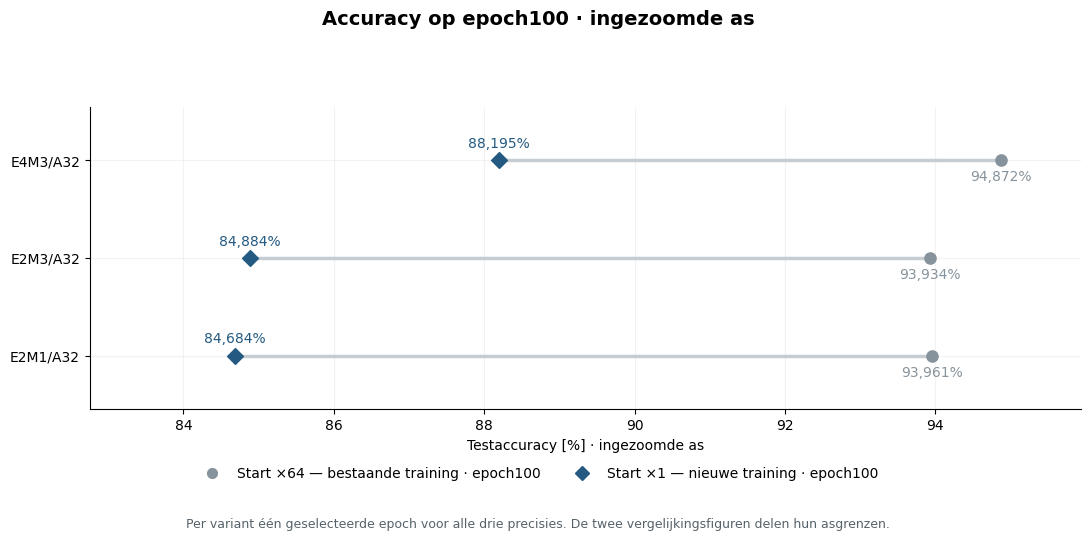

In [5]:
display(ns.initialization_checkpoint_table(run, 'endpoint').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
figures['accuracy_epoch100'] = ns.plot_initialization_checkpoints(run, 'endpoint')
display(figures['accuracy_epoch100'])
plt.close(figures['accuracy_epoch100'])


## 4. Vergelijking van de door E4M3 gekozen beste checkpoints

Beide varianten selecteren hun beste E4M3-checkpoint binnen **hetzelfde beschikbare epochvenster**. Bij een nieuwe deelrun van bijvoorbeeld50 epochs wordt de historische selectie eveneens tot50 beperkt. De gekozen epoch mag tussen varianten verschillen; alle drie precisies komen per variant steeds uit één checkpoint. Deze figuur gebruikt dezelfde asgrenzen als de epoch 100-vergelijking.

De officiële testset wordt volgens het bestaande protocol ook gebruikt voor checkpointselectie. De geselecteerde beste score is daarom geen onafhankelijke testschatting na selectie.

,Variant,Epoch,Precisie,Testaccuracy [%],Correct,Testbeelden,Selectievenster
0,Start ×64 — bestaande training,63,E4M3,95.029195,24738,26032,1–100
1,Start ×64 — bestaande training,63,E2M3,93.846036,24430,26032,1–100
2,Start ×64 — bestaande training,63,E2M1,93.700061,24392,26032,1–100
3,Start ×1 — nieuwe training,90,E4M3,88.206822,22962,26032,1–100
4,Start ×1 — nieuwe training,90,E2M3,83.662415,21779,26032,1–100
5,Start ×1 — nieuwe training,90,E2M1,84.227105,21926,26032,1–100


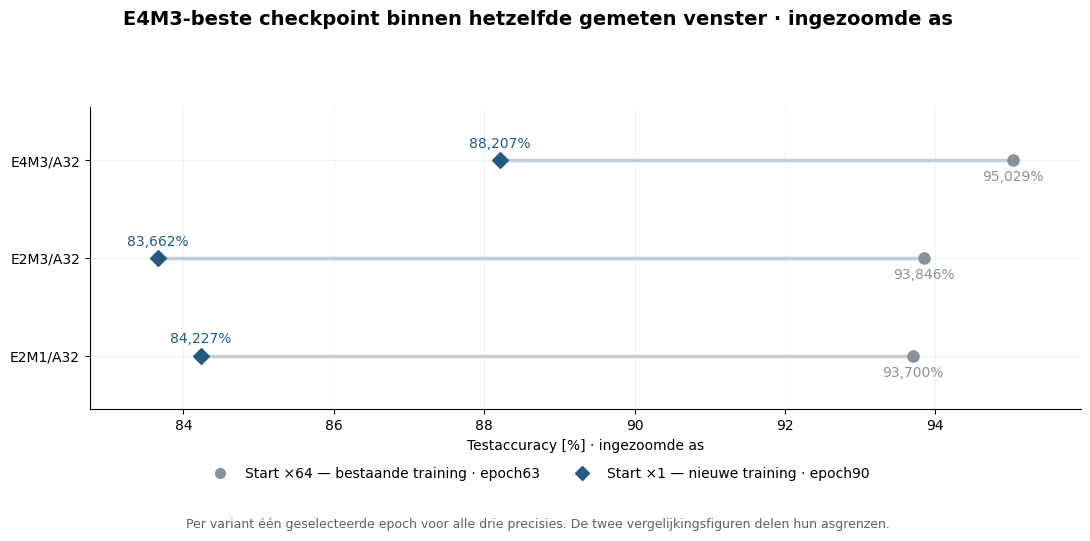

In [6]:
display(ns.initialization_checkpoint_table(run, 'best').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
figures['accuracy_best_E4M3'] = ns.plot_initialization_checkpoints(run, 'best')
display(figures['accuracy_best_E4M3'])
plt.close(figures['accuracy_best_E4M3'])


## 5. Afzonderlijke vijf-epochpilot: vroege herhaling

De eerdere init×1-pilot is een eigen run. De nieuwe training begint opnieuw. Onderstaande tabel vergelijkt uitsluitend beide echte epoch 5-metingen, zodra de nieuwe run die epoch heeft bereikt. Het behouden CUDA-beleid garandeert geen bitexacte herhaling, ook bij dezelfde seed en datavolgorde. Pilotmetingen worden niet als epochs van de nieuwe run ingevoegd.

In [7]:
display(ns.pilot_comparison_table(run).round(6))


,Run,Epoch,Precisie,Testaccuracy [%],Verschil t.o.v. pilot [pp]
0,Afzonderlijke init×1-pilot,5,E4M3,80.961893,0.000000
1,"Nieuwe100-epochrun, opnieuw gestart",5,E4M3,81.004149,0.042256
2,Afzonderlijke init×1-pilot,5,E2M3,81.538107,0.000000
3,"Nieuwe100-epochrun, opnieuw gestart",5,E2M3,79.751844,-1.786263
4,Afzonderlijke init×1-pilot,5,E2M1,81.718654,0.000000
5,"Nieuwe100-epochrun, opnieuw gestart",5,E2M1,80.251229,-1.467425


## 6. Evolutie van alle tien factoren

Epoch0 is de opgeslagen beginstaat. Iedere kolom toont de gemeten verdeling van de 4.080 groepen aan die epochgrens. Alle tien factoren blijven zichtbaar, inclusief nulcategorieën. Bij lange reeksen staat het percentage in de kleurschaal; de gedetailleerde tellingen blijven beschikbaar in de tabellen.

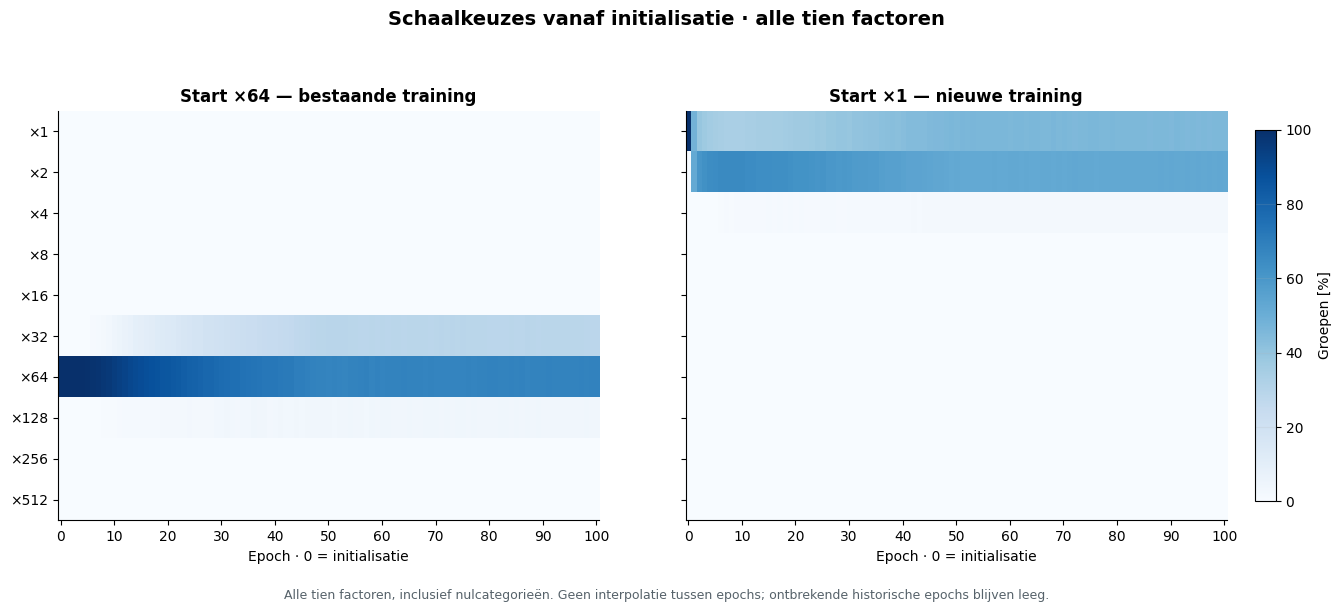

In [8]:
figures['factoren_per_epoch'] = ns.plot_factor_evolution(run)
display(figures['factoren_per_epoch'])
plt.close(figures['factoren_per_epoch'])


## 7. Aantallen en percentages bij de geselecteerde punten

De grafiek vergelijkt de beginstaat, de laatste nieuwe epoch en dezelfde historische epoch. De staven beginnen op nul. De tabellen bevatten daarnaast de verdeling bij het eigen E4M3-beste checkpoint. De gekozen factor is steeds een verhouding tot de actuele E4-bronschaal.

,Epoch,Factor,Groepen,Aandeel [%]
0,0,×1,4080,100.0
1,0,×2,0,0.0
2,0,×4,0,0.0
3,0,×8,0,0.0
4,0,×16,0,0.0
5,0,×32,0,0.0
6,0,×64,0,0.0
7,0,×128,0,0.0
8,0,×256,0,0.0
9,0,×512,0,0.0


,Epoch,Factor,Groepen,Aandeel [%]
0,90,×1,1848,45.2941
1,90,×2,2157,52.8676
2,90,×4,75,1.8382
3,90,×8,0,0.0000
4,90,×16,0,0.0000
5,90,×32,0,0.0000
6,90,×64,0,0.0000
7,90,×128,0,0.0000
8,90,×256,0,0.0000
9,90,×512,0,0.0000


,Epoch,Factor,Groepen,Aandeel [%]
0,100,×1,1852,45.3922
1,100,×2,2148,52.6471
2,100,×4,80,1.9608
3,100,×8,0,0.0000
4,100,×16,0,0.0000
5,100,×32,0,0.0000
6,100,×64,0,0.0000
7,100,×128,0,0.0000
8,100,×256,0,0.0000
9,100,×512,0,0.0000


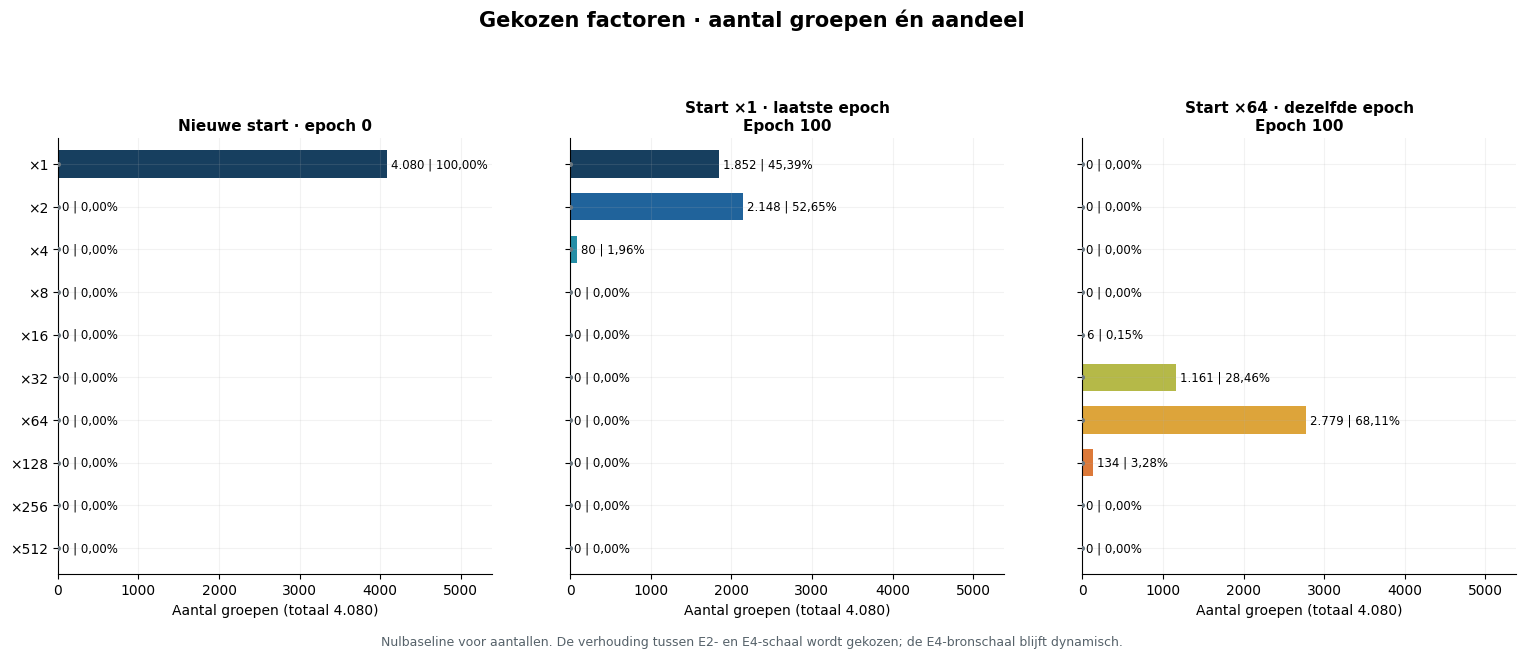

In [9]:
display(ns.factor_distribution_table(run, 0).round({'Aandeel [%]': 4}))
display(ns.factor_distribution_table(run, run.observed_best_epoch).round({'Aandeel [%]': 4}))
display(ns.factor_distribution_table(run).round({'Aandeel [%]': 4}))
figures['factoren_aantallen'] = ns.plot_factor_counts(run)
display(figures['factoren_aantallen'])
plt.close(figures['factoren_aantallen'])


## 8. Continue θ-ontwikkeling

De optimizer wijzigt een continue FP32-parameter; de voorwaartse stap gebruikt de afgeronde integeroffset. Een parameter kan dus bewegen zonder al een andere factor te kiezen. Gemiddelde, P05–P95 en minimum/maximum laten deze beweging zien. Horizontale lijnen liggen op de afrondingsdrempels0,5;1,5;…;8,5.

,Epoch,Laag,Groepen,Min θ,P05 θ,Mediaan θ,Gemiddelde θ,P95 θ,Max θ,Exact θ=0 [%],Factor ×1 [%]
0,0,Alle lagen,4080,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,100.000000
7,1,Alle lagen,4080,0.0,0.006006,0.514970,0.456071,0.773019,0.904091,1.568627,47.794118
14,2,Alle lagen,4080,0.0,0.007302,0.622693,0.557922,0.979123,1.196886,1.102941,39.411765
21,3,Alle lagen,4080,0.0,0.012669,0.663040,0.605216,1.096445,1.391259,0.710784,37.401961
28,4,Alle lagen,4080,0.0,0.013653,0.682116,0.638196,1.183526,1.541326,0.686275,35.857843
...,...,...,...,...,...,...,...,...,...,...,...
672,96,Alle lagen,4080,0.0,0.044096,0.524804,0.652868,1.432771,2.031872,0.294118,45.490196
679,97,Alle lagen,4080,0.0,0.044091,0.524777,0.652870,1.432759,2.031929,0.147059,45.196078
686,98,Alle lagen,4080,0.0,0.044088,0.524766,0.652872,1.432764,2.031945,0.196078,45.343137
693,99,Alle lagen,4080,0.0,0.044067,0.524759,0.652875,1.432743,2.031941,0.220588,45.343137


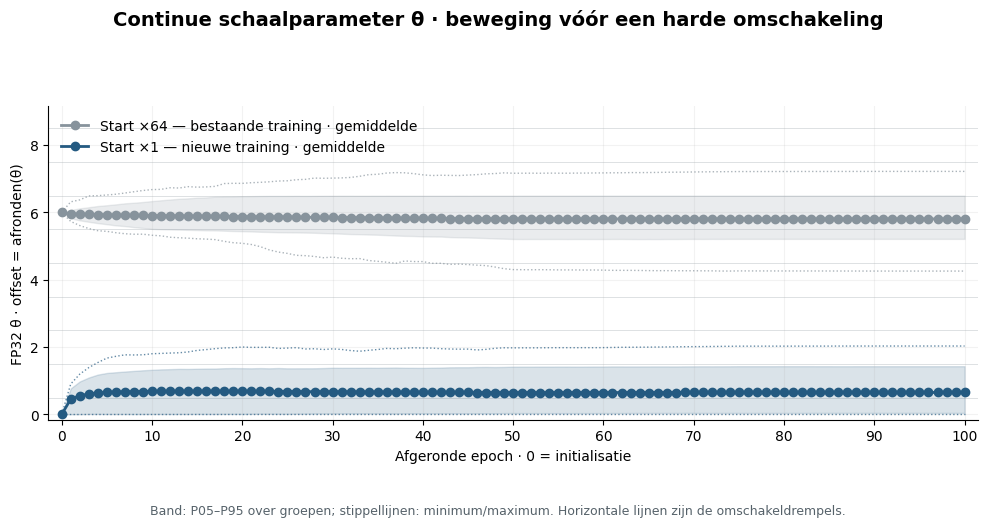

In [10]:
theta = ns.theta_summary_table(run)
display(theta.loc[theta.Laag.eq('Alle lagen')].round(6))
figures['theta_totaal'] = ns.plot_theta_evolution(run)
display(figures['theta_totaal'])
plt.close(figures['theta_totaal'])


## 9. Verschillen tussen lagen

De zes panelen delen hun y-as en tonen de continue parameters van de nieuwe init×1-training. Het bereik volgt de gemeten θ-waarden, zodat ook kleine verplaatsingen zichtbaar zijn. De tabel onderscheidt exact θ=0 van de afgeronde factor ×1.

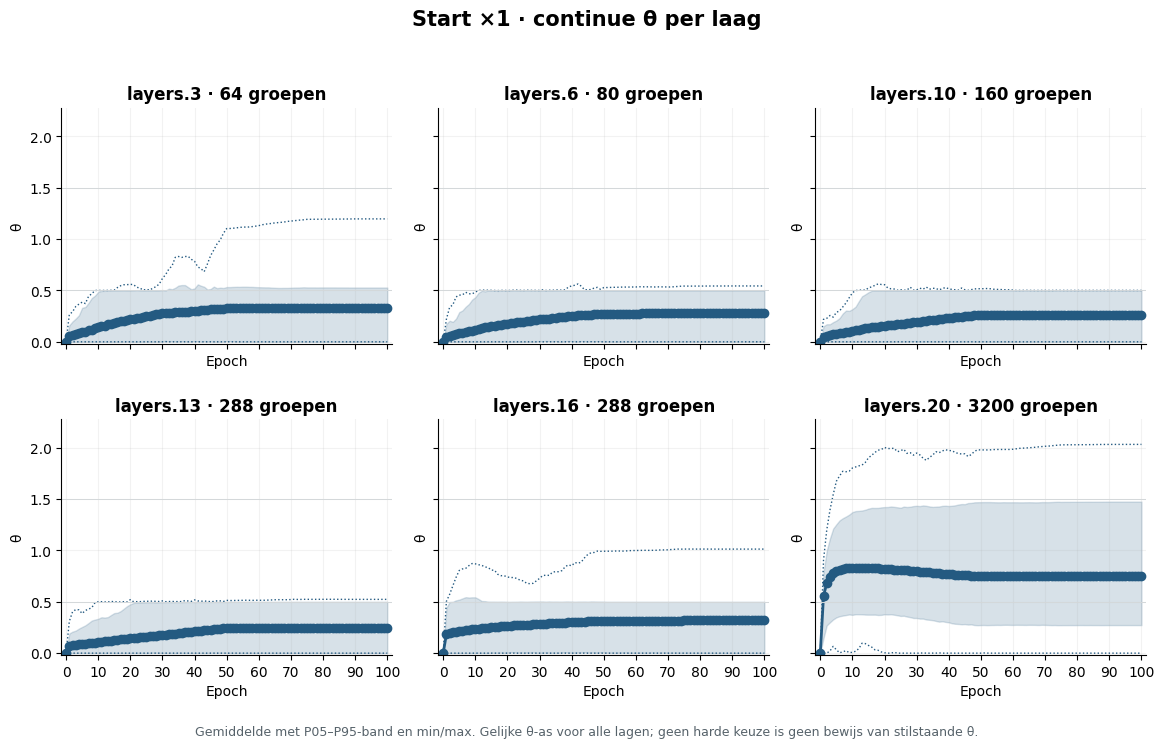

,Epoch,Laag,Gemiddelde θ,Min θ,Max θ,Exact θ=0 [%],Factor ×1 [%]
1,0,layers.10,0.000000,0.0,0.000000,100.000000,100.000000
2,0,layers.13,0.000000,0.0,0.000000,100.000000,100.000000
3,0,layers.16,0.000000,0.0,0.000000,100.000000,100.000000
4,0,layers.20,0.000000,0.0,0.000000,100.000000,100.000000
5,0,layers.3,0.000000,0.0,0.000000,100.000000,100.000000
...,...,...,...,...,...,...,...
702,100,layers.13,0.246532,0.0,0.523455,0.347222,97.569444
703,100,layers.16,0.317906,0.0,1.012814,0.000000,96.875000
704,100,layers.20,0.754720,0.0,2.032011,0.000000,31.437500
705,100,layers.3,0.331661,0.0,1.196488,1.562500,90.625000


In [11]:
figures['theta_per_laag'] = ns.plot_theta_by_layer(run)
display(figures['theta_per_laag'])
plt.close(figures['theta_per_laag'])
display(theta.loc[theta.Laag.ne('Alle lagen'), ['Epoch', 'Laag', 'Gemiddelde θ', 'Min θ', 'Max θ', 'Exact θ=0 [%]', 'Factor ×1 [%]']].round(6))


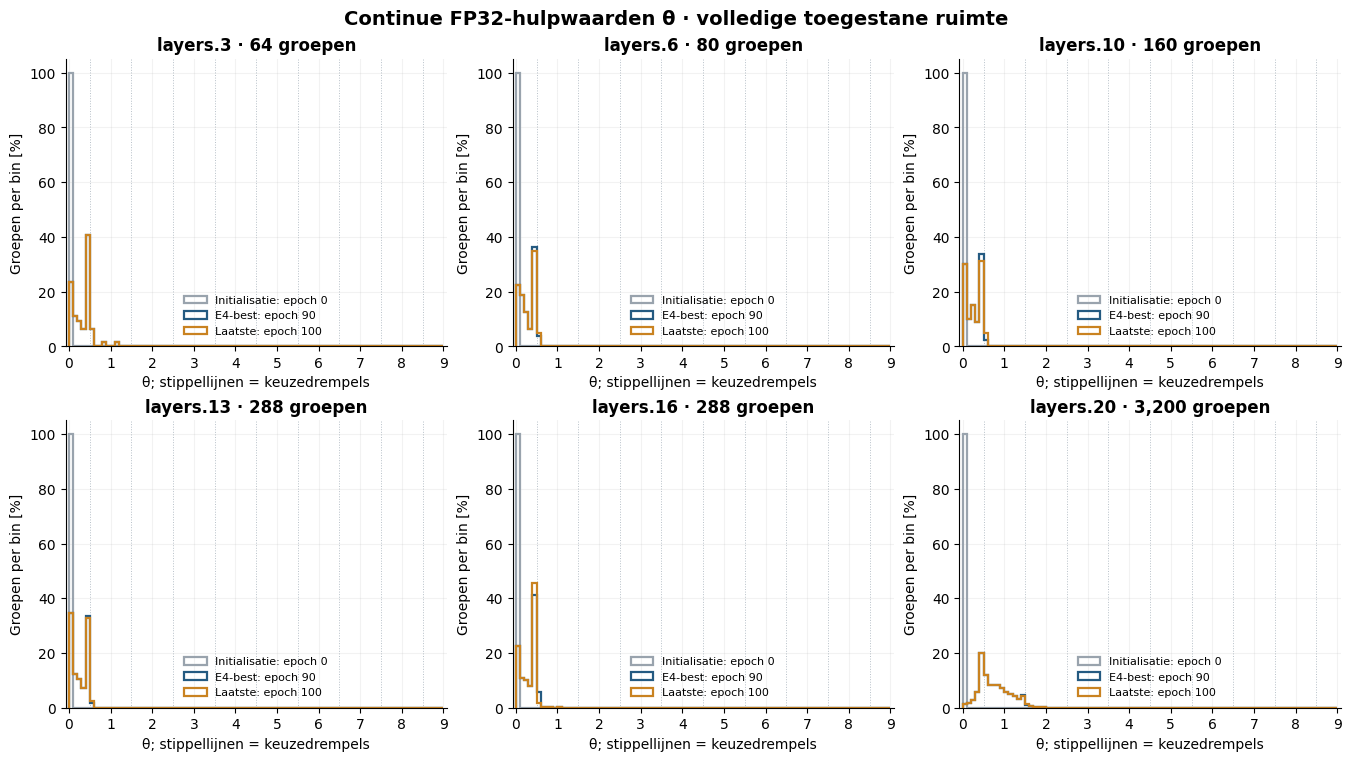

In [12]:
figures['theta_verdelingen'] = ns.plot_theta_distributions(run)
display(figures['theta_verdelingen'])
plt.close(figures['theta_verdelingen'])


## 10. Ondergrens, projecties en updates

Factor×1 betekent dat θ naar offset0 wordt afgerond; exact θ=0 betekent dat de parameter op de projectiegrens staat. Een update onder0 wordt op 0 geprojecteerd. Een groep kan binnen één epoch meerdere projecties of factorswitches ondergaan.

De gradientfiguur toont de grootste geregistreerde **laag-L2-norm** over batches, geen globale netwerkgradientnorm. Flips, unieke wisselende groepen en netto continue verplaatsing worden afzonderlijk bijgehouden.

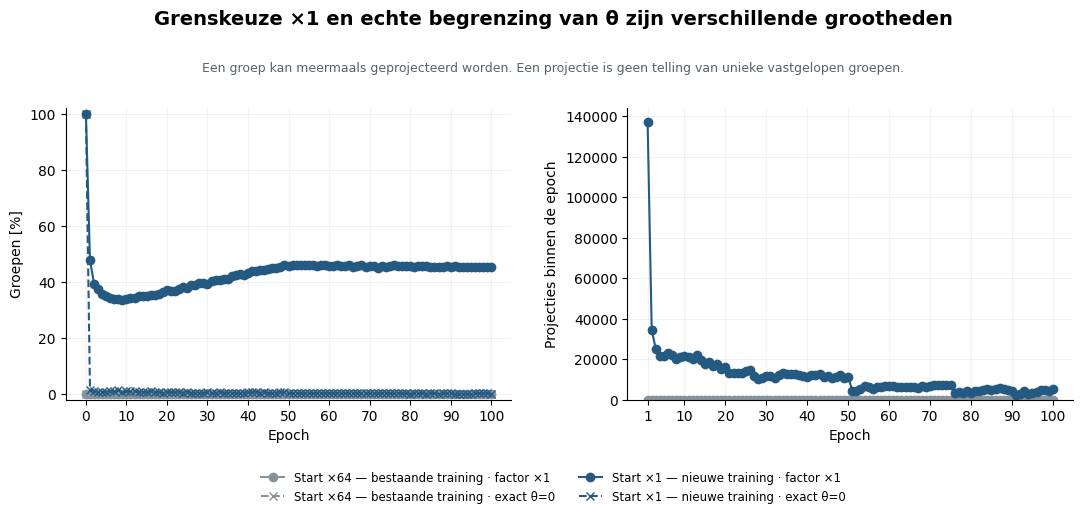

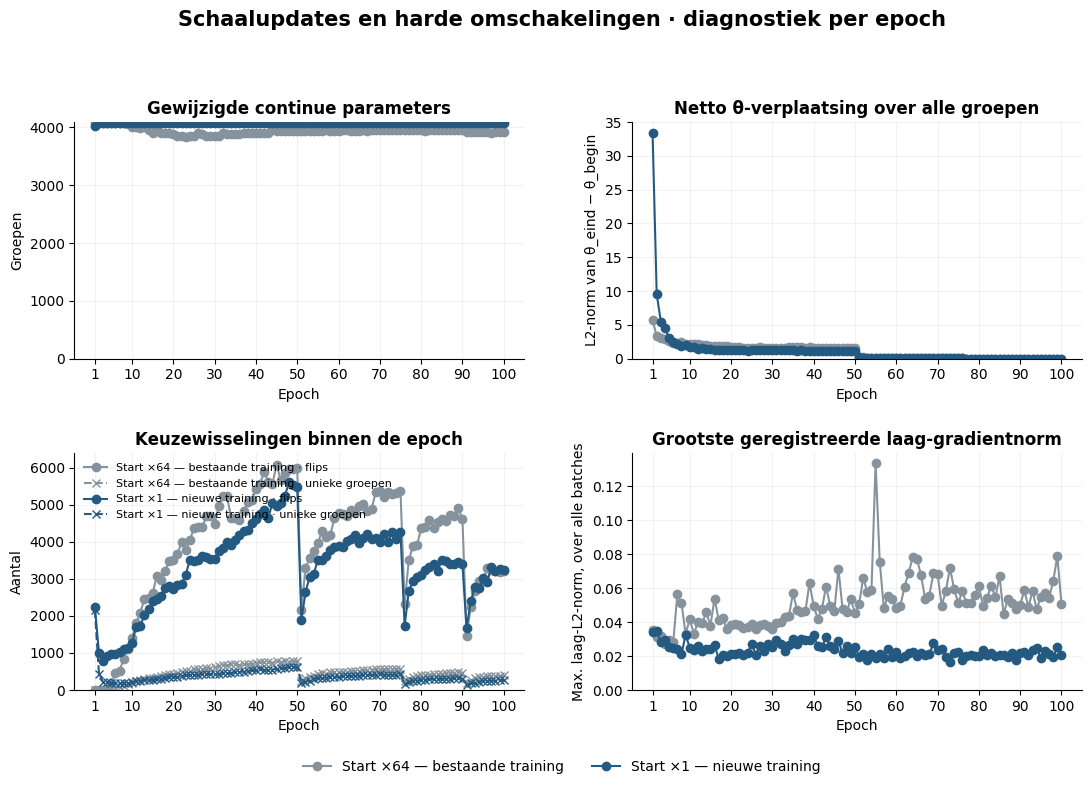

In [13]:
figures['grenzen_en_projecties'] = ns.plot_initialization_boundaries(run)
display(figures['grenzen_en_projecties'])
plt.close(figures['grenzen_en_projecties'])
figures['updates_en_gradients'] = ns.plot_initialization_updates(run)
display(figures['updates_en_gradients'])
plt.close(figures['updates_en_gradients'])


## 11. Losses en voorspelde klassen

E4M3 leert met harde label-CE. E2M3 leert van de detached E4M3-softmax; E2M1 leert van de detached E2M3-softmax. Deze trainobjectieven verschillen van harde test-CE en worden afzonderlijk getoond.

De voorspellingstellingen geven aan of een modus nog meerdere cijfers onderscheidt. Dit zijn geaggregeerde opgeslagen tellingen, geen nieuwe inferentie of gepaarde test op individuele beelden. Een lage accuracy of constante voorspelling is een onderzoeksuitkomst, geen automatische technische FAIL.

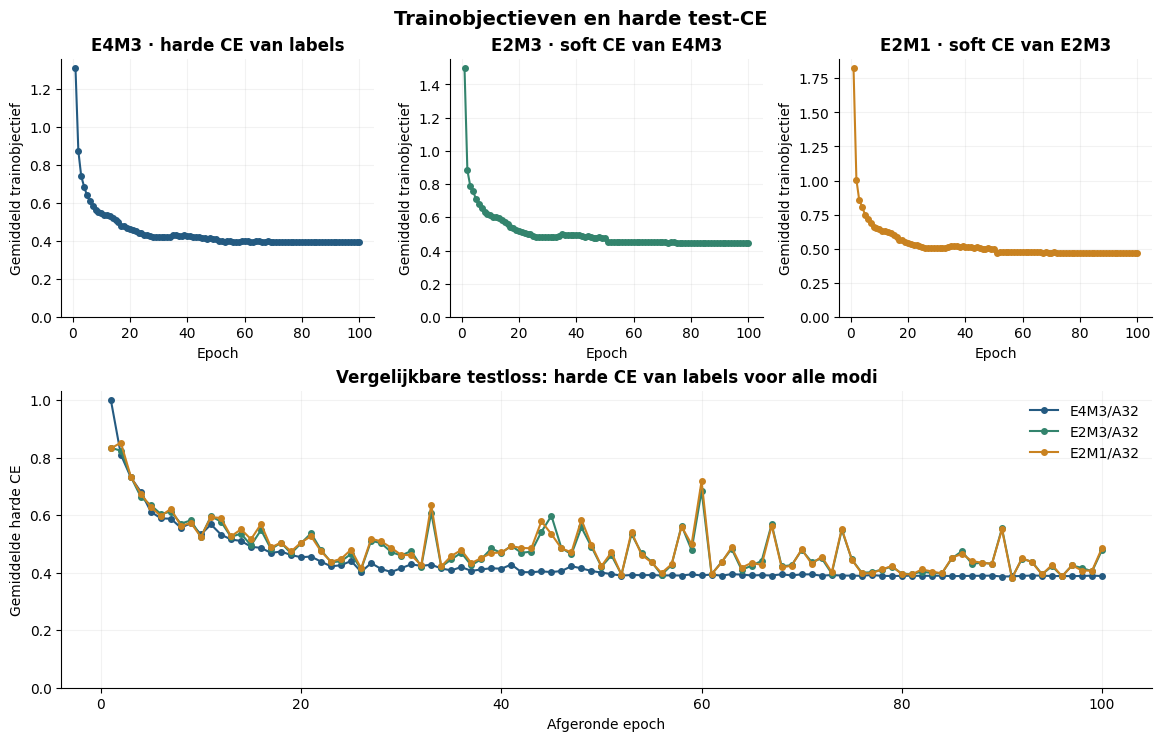

,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,100,MXFP8_E4M3,10,1,19.353104,19.587431,88.195298,False,26032,"[1732, 5038, 4222, 2894, 2586, 2459, 1896, 206...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,100,MXFP6_E2M3,10,1,23.743854,19.587431,84.883989,False,26032,"[1444, 6181, 3858, 2881, 2805, 2562, 1675, 193...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,100,MXFP4_E2M1,10,1,24.012754,19.587431,84.684235,False,26032,"[1414, 6251, 3852, 2882, 2808, 2601, 1668, 191...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,90,MXFP8_E4M3,10,1,19.572065,19.587431,88.206822,False,26032,"[1741, 5095, 4215, 2842, 2608, 2442, 1907, 206...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,90,MXFP6_E2M3,10,1,18.400430,19.587431,83.662415,False,26032,"[1728, 4790, 4332, 2410, 3743, 2178, 2119, 224...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,90,MXFP4_E2M1,10,1,18.281346,19.587431,84.227105,False,26032,"[1703, 4759, 4406, 2501, 3717, 2194, 2099, 220...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


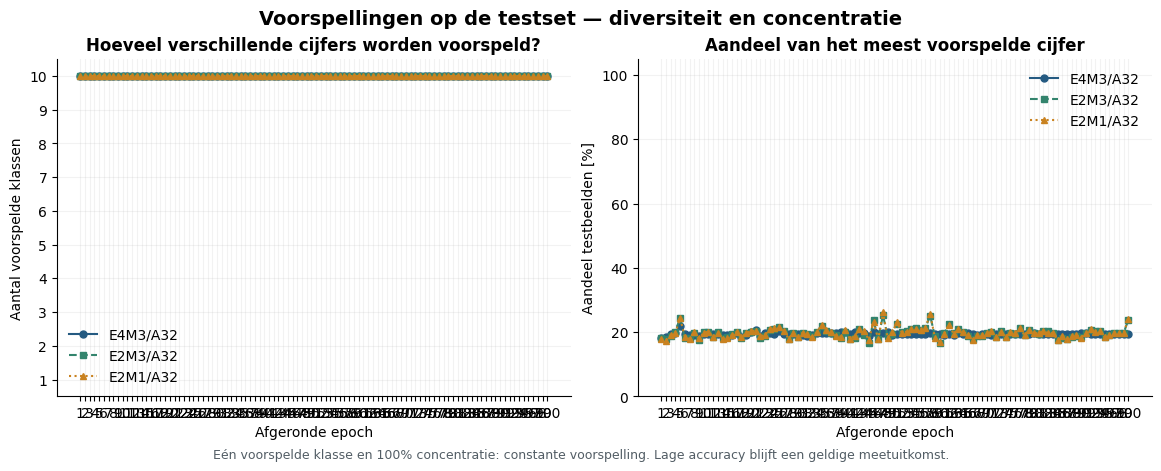

In [14]:
figures['losses'] = ns.plot_objectives(run)
display(figures['losses'])
plt.close(figures['losses'])
display(ns.prediction_table(run, selected_only=True))
figures['voorspelde_klassen'] = ns.plot_prediction_diversity(run)
display(figures['voorspelde_klassen'])
plt.close(figures['voorspelde_klassen'])


## 12. Duur en opslagkosten

De gewijzigde beginfactor voegt geen opties, parameters of trainingspasses toe. Een flexibele bron met tien keuzes bewaart4 bits per groep:2.040 bytes bij4.080 groepen. De4.080 FP32-hulpparameters, gradients en twee Adam-momenten vragen analytisch 65.280 bytes, exclusief framework en tijdelijke buffers.

Dit is geen meting van hardware-energie of native MX-uitvoering. Bij een deelrun blijft een looptijdprojectie duidelijk onderscheiden van gemeten tijd; na100 epochs wordt de werkelijke som van epochtijden gerapporteerd.

,Onderdeel,Waarde,Betekenis
0,FP32 schaalparameters,4080,Beide initialisaties hebben hetzelfde aantal t...
1,Gepakte keuze-informatie [bytes],2040,"Vier bits per B32-groep, tien mogelijke offsets."
2,θ + gradient + twee Adam-momenten [bytes],65280,Analytisch 4 × 4.080 × 4; exclusief framework ...
3,Nieuwe trainingspasses per minibatch,3,E4M3 → E2M3 → E2M1; dezelfde route als de init...


,Variant,Keuzebits per groep,Groepen,Compacte keuzebytes,Extra FP32 theta+gradient+Adam [bytes]
0,Vaste factor,0,4080,0,0
1,Twee leerbare keuzes,1,4080,510,65280
2,Tien leerbare keuzes,4,4080,2040,65280


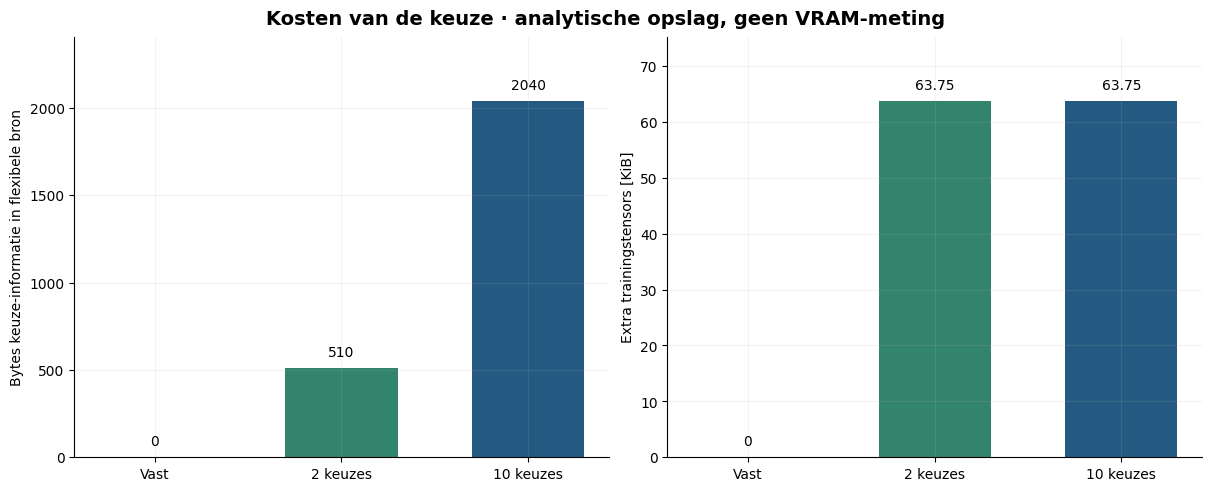

**Gemeten som over 100 afgeronde epochs: 6903.37 s (115.06 minuten).** Alle honderd epochs zijn aanwezig. De gemeten duur omvat train, test, epochcontroles en checkpointschrijven; een eerdere projectie wordt hiervoor niet gebruikt. Download, installatie, data-inladen, eindrapportage en sessiepauzes zijn niet inbegrepen.

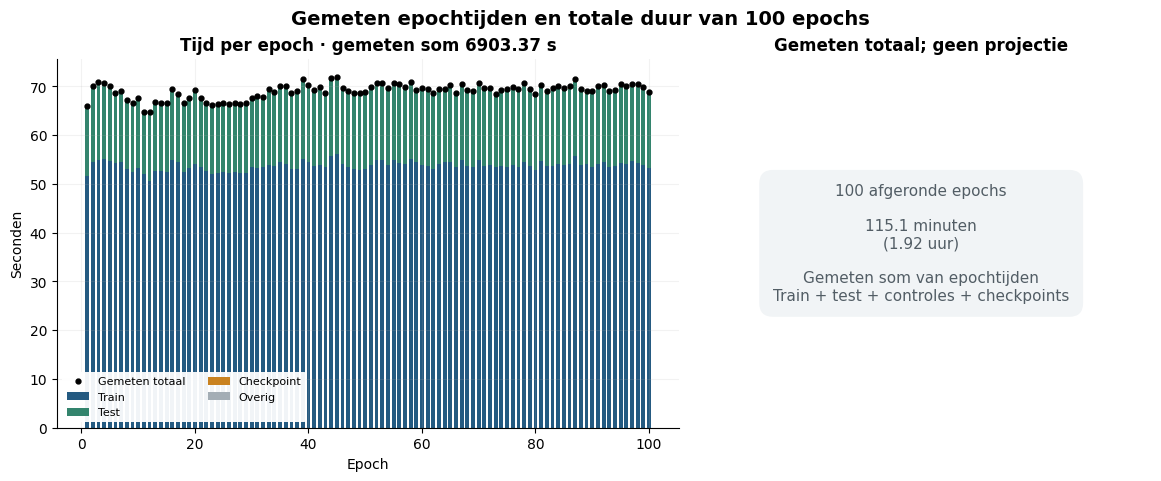

In [15]:
display(ns.initialization_cost_table(run))
display(ns.storage_cost_table(run))
figures['opslagkosten'] = ns.plot_storage_cost(run)
display(figures['opslagkosten'])
plt.close(figures['opslagkosten'])
display(Markdown(ns.timing_markdown(run)))
figures['epochtijden'] = ns.plot_timing(run)
display(figures['epochtijden'])
plt.close(figures['epochtijden'])


## 13. Technische controles en interpretatie

Onderstaande controles zijn tijdens de run opgeslagen. Deze notebook voert geen training, gradienttest of checkpointinferentie uit. De compacte exports bevatten één E4M3-bron met keuze-informatie; de lagere formaten worden uit die bron afgeleid.

**Te beoordelen:** verschuift de schaalverdeling vanuit×1 naar dezelfde regio als vanuit×64, en volgt de accuracy? Een verschil kan samenhangen met de start, geleidelijke optimalisatie, grensprojecties en gezamenlijke aanpassing van de gewichten. Eén run per initialisatie bewijst geen statistische superioriteit of globaal optimum. Ook100 epochs bewijzen op zichzelf geen convergentie.

Een afzonderlijke proef met onafhankelijke schalen per exponentformaat blijft een vervolgstap; die schalen worden hier niet ingevoerd. De oorspronkelijke onderzoeksdata blijven ongewijzigd.

In [16]:
display(ns.audit_table(run))
display(ns.export_table(run))
display(Markdown(ns.scale_learning_markdown(run)))
display(pd.DataFrame(run.issues, columns=['Niveau', 'Melding']))


,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten gecontroleerd,True
2,Geleerde schaalcorrectie ingeschakeld,True
3,Schaalkeuzes en θ-staten onafhankelijk consistent,True
4,E2M1 behoudt de E2M3-schaal,True
5,Eén E4-bron per laag en minibatch,True
6,Broncache leeg vóór iedere optimizerupdate,True
7,BN-tellers correct in elke opgeslagen epoch,True
8,Evaluatie zonder optimizerupdates,True
9,Bronbestanden ongewijzigd,True


,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes MX-masters afwezig,FP32-schaalproxies afwezig,Gepakte keuze-informatie [bytes],Eigen schaaloffsets,E4-bronschaal behouden,Afgeleid uit opgeslagen bron,Masters gelezen voor afleiding,Volledige testset opnieuw uitgevoerd,Bron-SHA256
0,best_E4M3_test,90,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,202009,True,True,True,2040,[0],True,False,False,False,783dde9748f31f4c2b0eda2b1d705d9fd9a628a7db1d02...
1,best_E4M3_test,90,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,169369,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,783dde9748f31f4c2b0eda2b1d705d9fd9a628a7db1d02...
2,best_E4M3_test,90,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,136793,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,783dde9748f31f4c2b0eda2b1d705d9fd9a628a7db1d02...
3,last_epoch,100,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,202009,True,True,True,2040,[0],True,False,False,False,fe17d248e24372711c201de76262d5eb2539ab2096de3b...
4,last_epoch,100,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,169369,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,fe17d248e24372711c201de76262d5eb2539ab2096de3b...
5,last_epoch,100,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,136793,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,fe17d248e24372711c201de76262d5eb2539ab2096de3b...


**Laatste afgeronde epoch 100 — aantallen per factor:** ×1: **1,852**, ×2: **2,148**, ×4: **80**, ×8: **0**, ×16: **0**, ×32: **0**, ×64: **0**, ×128: **0**, ×256: **0**, ×512: **0**. Totaal: 4,080 groepen. In de laatste epoch veranderden 4,074 FP32-hulpwaarden. Over de opgeslagen training werden 330,942 harde keuzewisselingen geteld.

**Uiterste keuzes:** 1,852 groepen kiezen ×1 en 0 kiezen ×512. **Exact op de projectiegrens:** 4 θ-waarden zijn 0 en 0 zijn 9. Een uiterste keuze betekent dus niet automatisch dat de continue parameter op de grens vastzit.

Een groep kan binnen een epoch meerdere keren wisselen. Het aantal wissels, het aantal unieke wisselende groepen en het verschil tussen de twee epochgrenzen zijn afzonderlijke metingen. Een sprong van offset5 naar7 telt als één wissel met sprongafstand2. Geen harde wissel sluit een continue θ-verplaatsing niet uit; geen van deze diagnostieken bewijst accuracywinst.

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Optioneel: figuren bewaren

De notebook blijft standaard alleen lezen en weergeven. Zet bovenaan `SAVE_FIGURES = True` om figuren en bronverwijzingen in een nieuwe analysemap te bewaren.

In [17]:
if SAVE_FIGURES:
    destination = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', destination)
else:
    print('Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.')
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,scale_epoch_metrics.csv
